In [1]:
import h5py
import pandas as pd
import plotly.express as px
import numpy as np
import matplotlib.pyplot as plt

DOUBLE_MACHINE_EPS = 2**-52
MATPLOTLIB_COLOR_IDX = 0
MATPLOTLIB_COLORS = ['b', 'g', 'r', 'c', 'm', 'y', 'k']
MATPLOTLIB_SHAPE_IDX = 0
MATPLOTLIB_SHAPES = ['.','o', '^', 's', 'P', 'X', 'D']

# for a given matrix type and a given implementation, plot boxplots of the componentwise nomalized error ratio for each dimension
def plot_all_componentwise_forward_error_constants_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, ax):

    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_gt_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == gt_impl)].sort_values(by="m")["matrix_id"]
    filtered_normalizing_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == "ABS_A_AND_B_" + gt_impl)].sort_values(by="m")["matrix_id"]

    # calculate componentwise forward error constants
    # note the potential divide-by-zero issue here
    dims = []
    all_forward_error_constants = []
    for mat_id, gt_mat_id, normalizing_mat_id in zip(filtered_ids, filtered_gt_ids, filtered_normalizing_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        gt_mat = matrices_dict[f"{gt_mat_id}"][:]
        normalizing_mat = matrices_dict[f"{normalizing_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        gt_vals = gt_mat.flatten()
        normalizing_vals = normalizing_mat.flatten()
        all_forward_error_constants.append(abs((vals - gt_vals) / (DOUBLE_MACHINE_EPS * normalizing_vals)))
    
    # plot
    ax.boxplot(all_forward_error_constants, labels=dims)
    ax.set_title(f"{impl.split('-')[0]}")
    #ax.set_yscale("log", base=2)
    ax.tick_params("x", rotation=45)

# for a given matrix type and a given implementation, plot the max of the componentwise nomalized error ratio for each dimension
def plot_max_componentwise_forward_error_constants_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict):

    global MATPLOTLIB_COLOR_IDX
    global MATPLOTLIB_COLORS
    global MATPLOTLIB_SHAPE_IDX
    global MATPLOTLIB_SHAPES

    
    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_gt_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == gt_impl)].sort_values(by="m")["matrix_id"]
    filtered_normalizing_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == "ABS_A_AND_B_" + gt_impl)].sort_values(by="m")["matrix_id"]

    # calculate max componentwise forward error constants
    # note the potential divide-by-zero issue here
    dims = []
    max_forward_error_constants = []
    for mat_id, gt_mat_id, normalizing_mat_id in zip(filtered_ids, filtered_gt_ids, filtered_normalizing_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        gt_mat = matrices_dict[f"{gt_mat_id}"][:]
        normalizing_mat = matrices_dict[f"{normalizing_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        gt_vals = gt_mat.flatten()
        normalizing_vals = normalizing_mat.flatten()
        max_forward_error_constants.append(max(abs((vals - gt_vals) / (DOUBLE_MACHINE_EPS * normalizing_vals))))
    
    # plot
    plt.xscale("log")
    plt.yscale("log")
    plt.scatter(dims, max_forward_error_constants, c = MATPLOTLIB_COLORS[MATPLOTLIB_COLOR_IDX], marker = MATPLOTLIB_SHAPES[MATPLOTLIB_SHAPE_IDX], label=f"{impl.split('-')[0]}")
    MATPLOTLIB_COLOR_IDX = (MATPLOTLIB_COLOR_IDX + 1)%len(MATPLOTLIB_COLORS)
    MATPLOTLIB_SHAPE_IDX = (MATPLOTLIB_SHAPE_IDX + 1)%len(MATPLOTLIB_SHAPES)
    plt.legend(loc='center left', bbox_to_anchor=(1,0.5))
    
# for a given matrix type and a given implementation, plot boxplots of the componentwise relative errors for each dimension
def plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, ax):

    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_gt_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == gt_impl)].sort_values(by="m")["matrix_id"]

    # calculate componentwise_unsigned_relative_errors
    # note the potential divide-by-zero issue here
    dims = []
    unsigned_relative_errors = []
    for mat_id, gt_mat_id in zip(filtered_ids, filtered_gt_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        gt_mat = matrices_dict[f"{gt_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        gt_vals = gt_mat.flatten()
        unsigned_relative_errors.append(abs((vals - gt_vals) / gt_vals))
    
    # plot
    ax.boxplot(unsigned_relative_errors, labels=dims)
    ax.set_title(f"{impl.split('-')[0]}")
    ax.set_yscale("log", base=2)
    ax.tick_params("x", rotation=45)

# for a given matrix type and a given implementation, plot boxplots of the componentwise absolute errors for each dimension
def plot_all_componentwise_unsigned_absolute_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, ax):

    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_gt_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == gt_impl)].sort_values(by="m")["matrix_id"]

    # calculate componentwise_unsigned_absolute_errors
    dims = []
    unsigned_absolute_errors = []
    for mat_id, gt_mat_id in zip(filtered_ids, filtered_gt_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        gt_mat = matrices_dict[f"{gt_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        gt_vals = gt_mat.flatten()
        unsigned_absolute_errors.append(abs(vals - gt_vals))
    
    # plot
    ax.boxplot(unsigned_absolute_errors, labels=dims)
    ax.set_title(f"{impl.split('-')[0]}")
    ax.set_yscale("log", base=2)
    ax.tick_params("x", rotation=45)

In [2]:
h5_file = h5py.File("grading_dgemm.h5", "r")

matrices_dict = h5_file["matrices"]

metadata_df = pd.DataFrame(h5_file["metadata"][:])
metadata_df["matrix_name"] = metadata_df["matrix_name"].str.decode("utf-8")
metadata_df["input_type"] = metadata_df["input_type"].str.decode("utf-8")
metadata_df["matrix_name"].unique()

array(['A', 'B', 'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
       'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
       'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
       'CUBLAS-12.9-unknown-unknown-NVCC8.0',
       'OZIMMU_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'STRASSEN_BASECASE_2-57e69bd-GNU_13.2-O0-x86_64_zen3',
       'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'ABS_A_AND_B_NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3'],
      dtype=object)

In [3]:
gt_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3"

impls = [
    'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
    'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
    'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
    'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
    'CUBLAS-12.9-unknown-unknown-NVCC8.0',
    'OZIMMU_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
    'STRASSEN_BASECASE_2-57e69bd-GNU_13.2-O0-x86_64_zen3',
    #'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
    #'ABS_A_AND_B_NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3'
]

<Figure size 432x288 with 0 Axes>

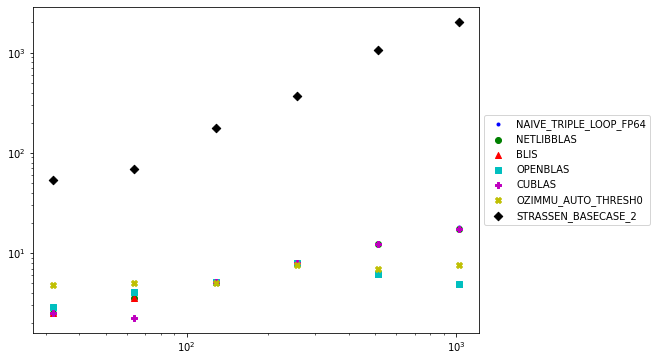

In [24]:
input_type = "U_0_1"

plt.clf()
plt.figure(figsize=(8,6))
for impl in impls:
    plot_max_componentwise_forward_error_constants_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict)
plt.show()

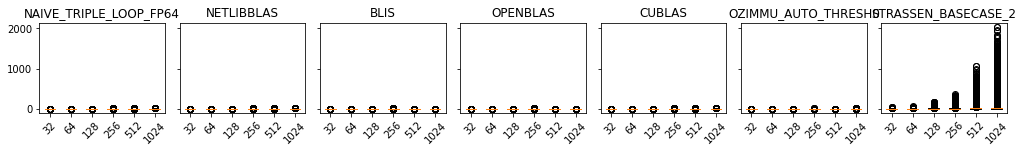

In [30]:
input_type = "U_0_1"

sharey=True

#fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=sharey, constrained_layout=True)
#for subplot_idx, impl in enumerate(impls):
#    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=sharey, constrained_layout=True)
for subplot_idx, impl in enumerate(impls):
    plot_all_componentwise_forward_error_constants_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

<Figure size 432x288 with 0 Axes>

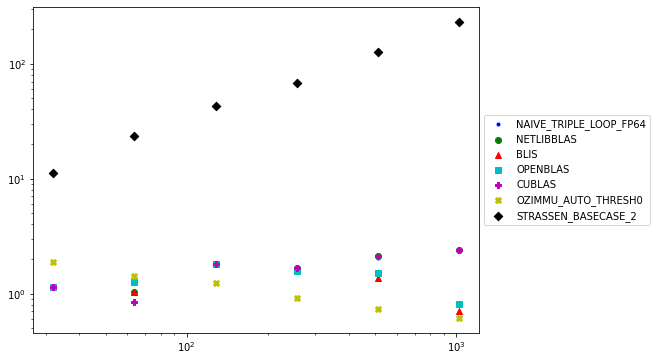

In [25]:
input_type = "U_-1_1"

plt.clf()
plt.figure(figsize=(8,6))
for impl in impls:
    plot_max_componentwise_forward_error_constants_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict)
plt.show()

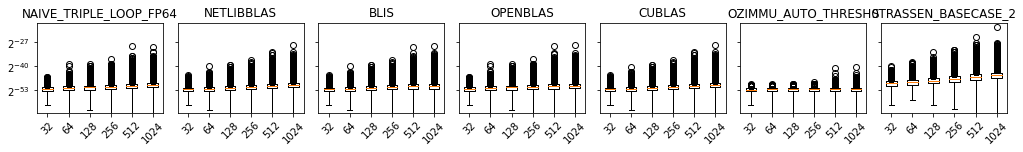

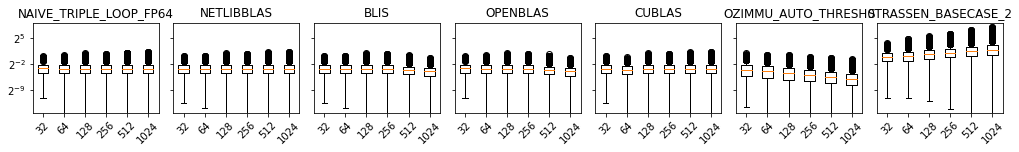

In [7]:
input_type = "U_-1_1"

sharey=True

fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=sharey, constrained_layout=True)
for subplot_idx, impl in enumerate(impls):
    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=sharey, constrained_layout=True)
for subplot_idx, impl in enumerate(impls):
    plot_all_componentwise_forward_error_constants_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

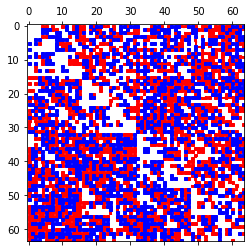

In [8]:
matrix_id = metadata_df[
    (metadata_df["matrix_name"] == 'STRASSEN_BASECASE_2-57e69bd-GNU_13.2-O0-x86_64_zen3') &
    (metadata_df["m"] == 64) &
    (metadata_df["input_type"] == "test1c")
]["matrix_id"]

A = matrices_dict[f"{matrix_id.iloc[0]}"][:]
plt.clf()
markersize=3
plt.spy(A>0, markersize=markersize, c="r")
plt.spy(A==0, markersize=markersize, c="w")
plt.spy(A<0, markersize=markersize, c="b")
plt.show()

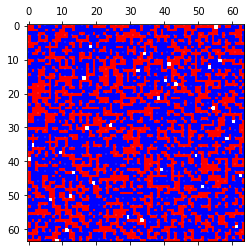

In [12]:
matrix_id = metadata_df[
    (metadata_df["matrix_name"] == 'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3') &
    (metadata_df["m"] == 64) &
    (metadata_df["input_type"] == "test1b")
]["matrix_id"]

A = matrices_dict[f"{matrix_id.iloc[0]}"][:]
plt.clf()
markersize=3
plt.spy(A>0, markersize=markersize, c="r")
plt.spy(A==0, markersize=markersize, c="w")
plt.spy(A<0, markersize=markersize, c="b")
plt.show()

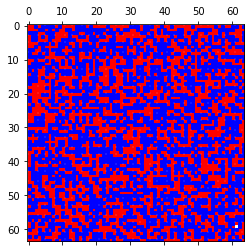

In [13]:
matrix_id = metadata_df[
    (metadata_df["matrix_name"] == 'STRASSEN_BASECASE_2-57e69bd-GNU_13.2-O0-x86_64_zen3') &
    (metadata_df["m"] == 64) &
    (metadata_df["input_type"] == "test1b")
]["matrix_id"]

A = matrices_dict[f"{matrix_id.iloc[0]}"][:]
plt.clf()
markersize=3
plt.spy(A>0, markersize=markersize, c="r")
plt.spy(A==0, markersize=markersize, c="w")
plt.spy(A<0, markersize=markersize, c="b")
plt.show()

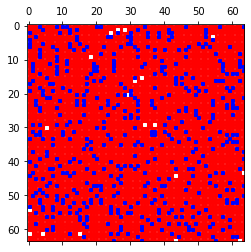

In [20]:
matrix_id = metadata_df[
    (metadata_df["matrix_name"] == 'STRASSEN_BASECASE_2-57e69bd-GNU_13.2-O0-x86_64_zen3') &
    (metadata_df["m"] == 64) &
    (metadata_df["input_type"] == "jim_test3c")
]["matrix_id"]

A = matrices_dict[f"{matrix_id.iloc[0]}"][:]
plt.clf()
markersize=3
plt.spy(A>0, markersize=markersize, c="r")
plt.spy(A==0, markersize=markersize, c="w")
plt.spy(A<0, markersize=markersize, c="b")
plt.show()

<Figure size 432x288 with 0 Axes>

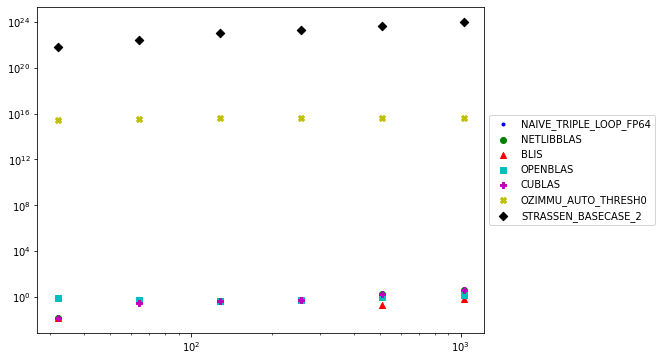

In [26]:
input_type = "jim_test3a"

plt.clf()
plt.figure(figsize=(8,6))
for impl in impls:
    plot_max_componentwise_forward_error_constants_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict)
plt.show()

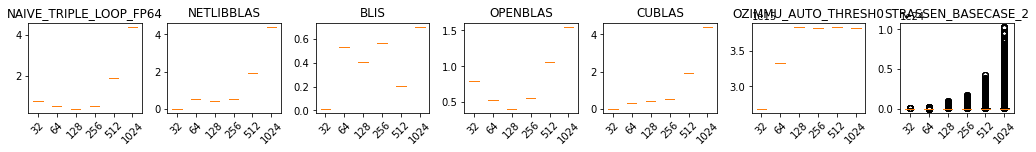

In [31]:
input_type = "jim_test3a"

sharey=False

#fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=sharey, constrained_layout=True)
#for subplot_idx, impl in enumerate(impls):
#    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=sharey, constrained_layout=True)
for subplot_idx, impl in enumerate(impls):
    plot_all_componentwise_forward_error_constants_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

<Figure size 432x288 with 0 Axes>

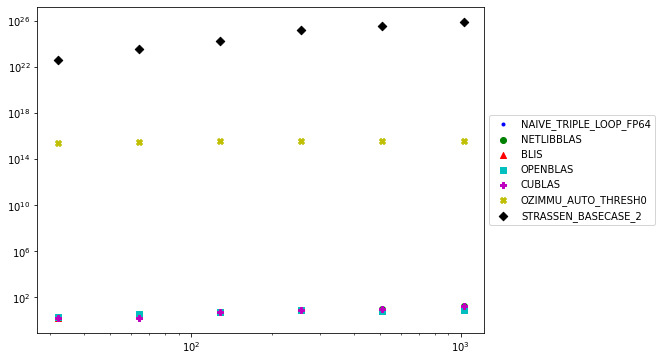

In [27]:
input_type = "jim_test3b"

plt.clf()
plt.figure(figsize=(8,6))
for impl in impls:
    plot_max_componentwise_forward_error_constants_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict)
plt.show()

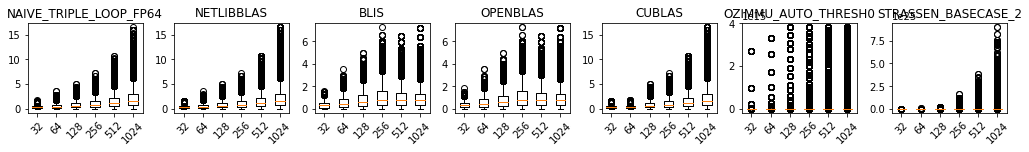

In [32]:
input_type = "jim_test3b"

sharey=False

#fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=sharey, constrained_layout=True)
#for subplot_idx, impl in enumerate(impls):
#    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=sharey, constrained_layout=True)
for subplot_idx, impl in enumerate(impls):
    plot_all_componentwise_forward_error_constants_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

<Figure size 432x288 with 0 Axes>

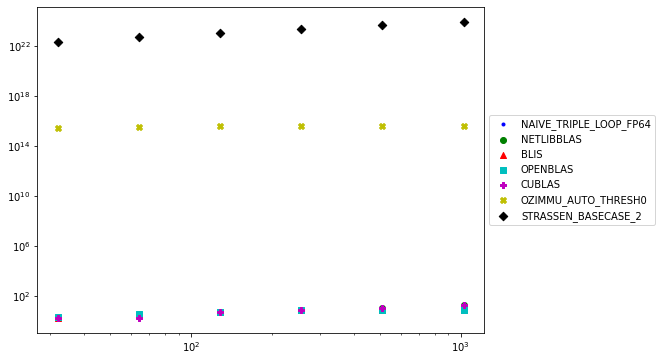

In [28]:
input_type = "jim_test3c"

plt.clf()
plt.figure(figsize=(8,6))
for impl in impls:
    plot_max_componentwise_forward_error_constants_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict)
plt.show()

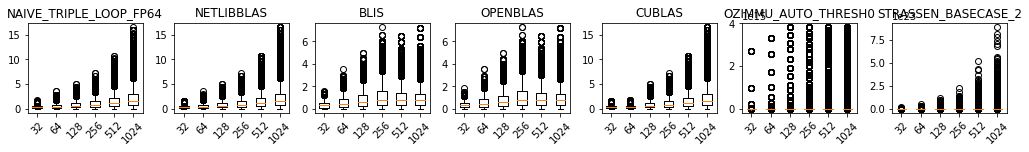

In [33]:
input_type = "jim_test3c"

sharey=False

#fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=sharey, constrained_layout=True)
#for subplot_idx, impl in enumerate(impls):
#   plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=sharey, constrained_layout=True)
for subplot_idx, impl in enumerate(impls):
    plot_all_componentwise_forward_error_constants_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])